# 03 · Modelling, Evaluation and Explainability

**What we predict**
- **Probability of default (PD).** This drives the risk band, eligibility and limit. We model it on the **log-odds** scale, which turns a skewed 0–1 number into a smooth, unbounded target.
- **Financial Health Score (0–100)** and the **6 pillar scores**, shown on the card.

**How we judge models** (held-out test set, 7,500 businesses)
- Regression fit: R² and MAE against the supplied PD and scores.
- Decision quality: risk-band accuracy, eligibility accuracy, AUC for "High risk".
- Credit ranking: Gini and KS on **simulated defaults**. The data has no real outcomes, so we draw a default for each business with probability equal to its supplied PD. The supplied PD itself sets the **ceiling** we can reach.

**Candidates**
1. **Ridge regression** (scorecard-style baseline: what most banks start with).
2. **LightGBM** (gradient-boosted trees), unconstrained.
3. **LightGBM with monotonic constraints** (behaves the way credit common sense expects).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import lightgbm as lgb
from sklearn.metrics import r2_score, confusion_matrix
from sklearn.model_selection import train_test_split

from msme_health.config import DATA_PATH, PILLARS, RANDOM_STATE, CATEGORICAL, NUMERIC_RAW
from msme_health.features import MODEL_FEATURES, PD_MONOTONE, LABELS, add_derived, prepare, monotone_vector
from msme_health.train import band, fit_lgb, linear_baseline, logit, pd_metrics, sigmoid, LGB_PARAMS

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

raw = pd.read_csv(DATA_PATH)
X = prepare(raw)
F = add_derived(raw)
strat = raw.Customer_Segment + "_" + raw.Credit_Risk_Category
tr, tmp = train_test_split(raw.index, test_size=0.30, stratify=strat, random_state=RANDOM_STATE)
va, te = train_test_split(tmp, test_size=0.50, stratify=strat[tmp], random_state=RANDOM_STATE)
z = pd.Series(logit(raw.Probability_of_Default.to_numpy()), index=raw.index)
rng = np.random.default_rng(RANDOM_STATE)
y_sim = (rng.random(len(raw)) < raw.Probability_of_Default.to_numpy()).astype(int)
true_te = raw.loc[te, "Probability_of_Default"].to_numpy()
print(f"train {len(tr):,} · validation {len(va):,} · test {len(te):,}  (stratified by segment × risk band)")
print(f"Simulated default rate: {y_sim.mean():.1%} (mean supplied PD {raw.Probability_of_Default.mean():.1%})")

train 35,000 · validation 7,500 · test 7,500  (stratified by segment × risk band)
Simulated default rate: 11.9% (mean supplied PD 11.9%)


## 1. Head-to-head on default probability

In [2]:
mono = monotone_vector(MODEL_FEATURES, PD_MONOTONE)
models = {
    "Ridge baseline": linear_baseline().fit(F.loc[tr], z[tr]),
    "LightGBM": fit_lgb(X.loc[tr], z[tr], X.loc[va], z[va]),
    "LightGBM monotonic": fit_lgb(X.loc[tr], z[tr], X.loc[va], z[va], monotone=mono),
}
preds = {
    "Ridge baseline": sigmoid(models["Ridge baseline"].predict(F.loc[te])),
    "LightGBM": sigmoid(models["LightGBM"].predict(X.loc[te])),
    "LightGBM monotonic": sigmoid(models["LightGBM monotonic"].predict(X.loc[te])),
}
res = pd.DataFrame({k: pd_metrics(true_te, v, y_sim[te]) for k, v in preds.items()}).T
ceiling = pd_metrics(true_te, true_te, y_sim[te])
res.loc["Supplied PD (ceiling)"] = ceiling
res

,pd_r2,pd_mae,logit_r2,risk_band_accuracy,high_risk_auc,eligibility_accuracy,sim_default_auc,sim_default_gini,sim_default_ks
Ridge baseline,0.9177,0.0193,0.9045,0.8321,0.9790,0.9244,0.7340,0.4680,0.3552
LightGBM,0.9124,0.0198,0.8992,0.8303,0.9778,0.9225,0.7324,0.4649,0.3521
LightGBM monotonic,0.9121,0.0199,0.8989,0.8291,0.9773,0.9237,0.7328,0.4656,0.3499
Supplied PD (ceiling),1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.7414,0.4828,0.3661


**Key result: the simple Ridge model matches (even slightly beats) LightGBM.**

Why? The EDA showed every driver has a smooth, monotonic link to PD, and PD is close to a linear function of the inputs plus random noise. Trees have nothing non-linear to discover. Their extra flexibility only fits noise.

Gini on simulated defaults reaches about **0.47 against a ceiling of 0.48**. Even a perfect copy of the supplied PD could not do much better, because the simulated defaults are random draws.

## 2. How much of the target is just noise?

If we hand a model the *true pillar scores* (information we could never have in production), how well can it predict the overall score? That tells us the **irreducible noise** in the target.

In [3]:
y = raw.Financial_Health_Score
Xp = pd.concat([X, raw[list(PILLARS)]], axis=1)
oracle = fit_lgb(Xp.loc[tr], y[tr], Xp.loc[va], y[va])
ours = fit_lgb(X.loc[tr], y[tr], X.loc[va], y[va], monotone=[-m for m in mono])
ridge = linear_baseline().fit(F.loc[tr], y[tr])
tbl = pd.Series({
    "Ridge on business data": r2_score(y[te], ridge.predict(F.loc[te])),
    "LightGBM on business data": r2_score(y[te], ours.predict(X.loc[te])),
    "Oracle: business data + true pillars": r2_score(y[te], oracle.predict(Xp.loc[te])),
}, name="R² on overall score").round(4)
tbl.to_frame()

,R² on overall score
Ridge on business data,0.8796
LightGBM on business data,0.8756
Oracle: business data + true pillars,0.8757


**Takeaway:** even the oracle tops out around the same R². The remaining ~12% of the score's variance is **random noise added by the data generator**. No model can predict it. We are at the ceiling.

## 3. Do the derived features help? (ablation)

In [4]:
raw_only = CATEGORICAL + NUMERIC_RAW
abl = {}
for name, feats in {"Raw columns only": raw_only, "Raw + derived": MODEL_FEATURES}.items():
    m = lgb.LGBMRegressor(**{**LGB_PARAMS, "n_estimators": 1500}).fit(
        X.loc[tr, feats], z[tr], eval_set=[(X.loc[va, feats], z[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    p = sigmoid(m.predict(X.loc[te, feats]))
    abl[name] = {"PD R²": r2_score(true_te, p), "Band accuracy": (band(true_te) == band(p)).mean()}
pd.DataFrame(abl).T.round(4)

,PD R²,Band accuracy
Raw columns only,0.9127,0.8299
Raw + derived,0.9124,0.8303


**Takeaway:** derived features add little *accuracy* here, because the supplied PD was built from the raw columns directly. They still earn their place:
- they make **explanations** readable ("cash surplus margin is low" vs "debits are ₹4.8 L");
- they power the **anomaly rules** and the **seasonal stress test**;
- on real default data, ratios typically add lift.

## 4. Monotonic constraints: cost vs benefit

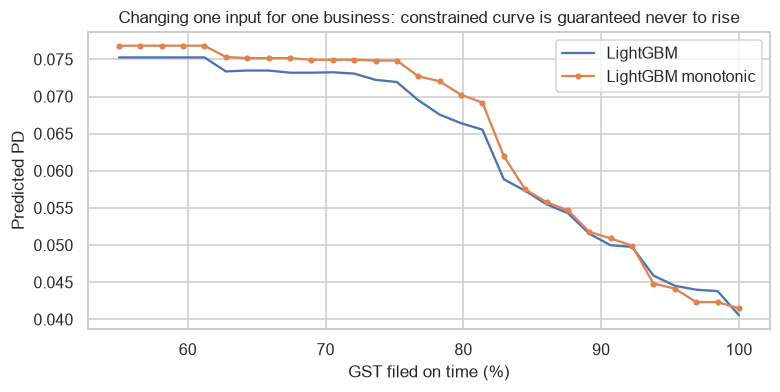

Accuracy cost of constraints (PD R²): 0.0003


In [5]:
base_row = raw.loc[te].iloc[[0]].copy()
grid = np.linspace(55, 100, 30)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ["LightGBM", "LightGBM monotonic"]:
    rows = pd.concat([base_row] * len(grid), ignore_index=True)
    rows["GST_Filing_Timeliness_Pct"] = grid
    ax.plot(grid, sigmoid(models[name].predict(prepare(rows))), label=name, marker="." if "mono" in name else None)
ax.set_xlabel("GST filed on time (%)")
ax.set_ylabel("Predicted PD")
ax.set_title("Changing one input for one business: constrained curve is guaranteed never to rise")
ax.legend()
plt.show()
print("Accuracy cost of constraints (PD R²):", round(res.loc["LightGBM", "pd_r2"] - res.loc["LightGBM monotonic", "pd_r2"], 4))

**Takeaway:** the constraints cost essentially nothing. In exchange, we get a guarantee that *improving* a behaviour can never *raise* risk. That matters for:
- regulators and fair-lending reviews;
- the what-if simulator shown to business owners;
- stability when the data drifts.

## 5. Calibration and errors

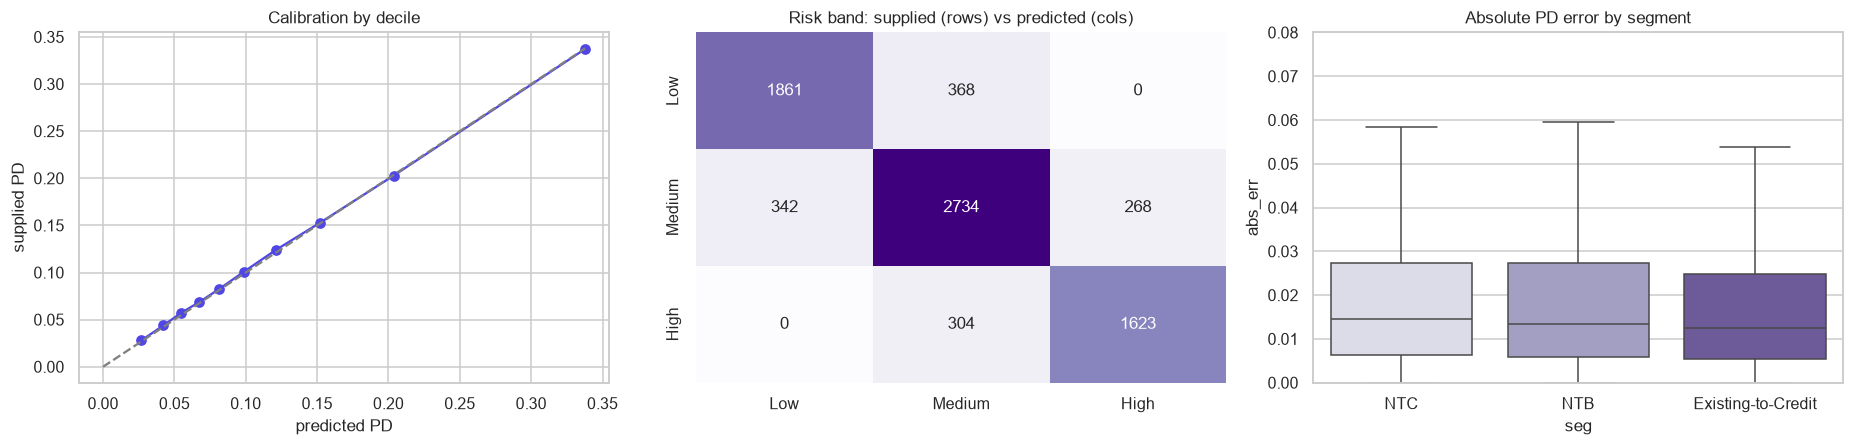

In [6]:
p = preds["LightGBM monotonic"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
cal = pd.DataFrame({"pred": p, "true": true_te})
cal["bin"] = pd.qcut(cal.pred, 10, labels=False)
g = cal.groupby("bin").mean()
axes[0].plot(g.pred, g.true, marker="o", color="#4F46E5")
axes[0].plot([0, g.max().max()], [0, g.max().max()], ls="--", color="grey")
axes[0].set_title("Calibration by decile")
axes[0].set_xlabel("predicted PD")
axes[0].set_ylabel("supplied PD")
cm = pd.DataFrame(confusion_matrix(band(true_te), band(p), labels=["Low", "Medium", "High"]),
                  index=["Low", "Medium", "High"], columns=["Low", "Medium", "High"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", ax=axes[1], cbar=False)
axes[1].set_title("Risk band: supplied (rows) vs predicted (cols)")
seg = raw.loc[te, "Customer_Segment"].to_numpy()
err = pd.DataFrame({"seg": seg, "abs_err": np.abs(p - true_te)})
sns.boxplot(data=err, x="seg", y="abs_err", ax=axes[2], fliersize=0, palette="Purples", order=["NTC", "NTB", "Existing-to-Credit"])
axes[2].set_ylim(0, 0.08)
axes[2].set_title("Absolute PD error by segment")
plt.tight_layout()
plt.show()

In [7]:
seg_tbl = pd.DataFrame({s: pd_metrics(true_te[seg == s], p[seg == s], y_sim[te][seg == s]) for s in ["NTC", "NTB", "Existing-to-Credit"]}).T
seg_tbl[["pd_r2", "risk_band_accuracy", "eligibility_accuracy", "high_risk_auc", "sim_default_gini"]]

,pd_r2,risk_band_accuracy,eligibility_accuracy,high_risk_auc,sim_default_gini
NTC,0.9121,0.8250,0.9234,0.9786,0.4752
NTB,0.9126,0.8370,0.9216,0.9763,0.4568
Existing-to-Credit,0.9103,0.8266,0.9265,0.9763,0.4504


**Takeaway:**
- The model is well calibrated.
- Band errors happen only between **neighbouring** bands (never Low ↔ High).
- Accuracy for **NTC businesses is as good as for existing borrowers**. The model does not need bureau history to work.

## 6. Explainability with SHAP

SHAP splits each prediction into contributions from each feature. These add up exactly from the average business's prediction to this business's prediction.

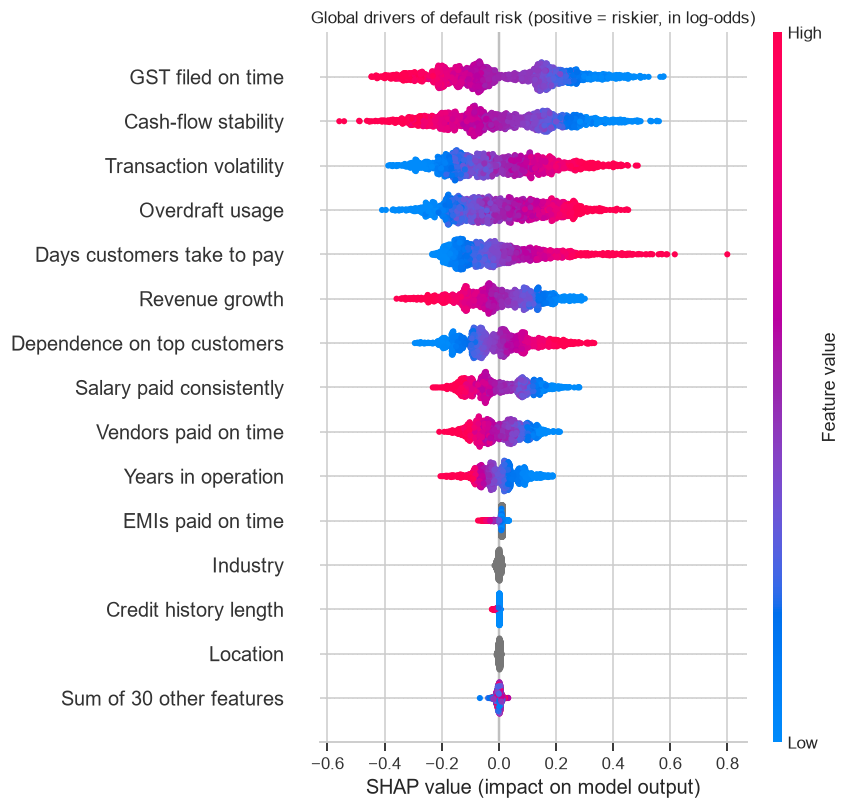

In [8]:
expl = shap.TreeExplainer(models["LightGBM monotonic"])
sm = X.loc[te].sample(2000, random_state=0)
sv = expl(sm)
sv.feature_names = [LABELS.get(f, f) for f in MODEL_FEATURES]
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Global drivers of default risk (positive = riskier, in log-odds)")
plt.tight_layout()
plt.show()

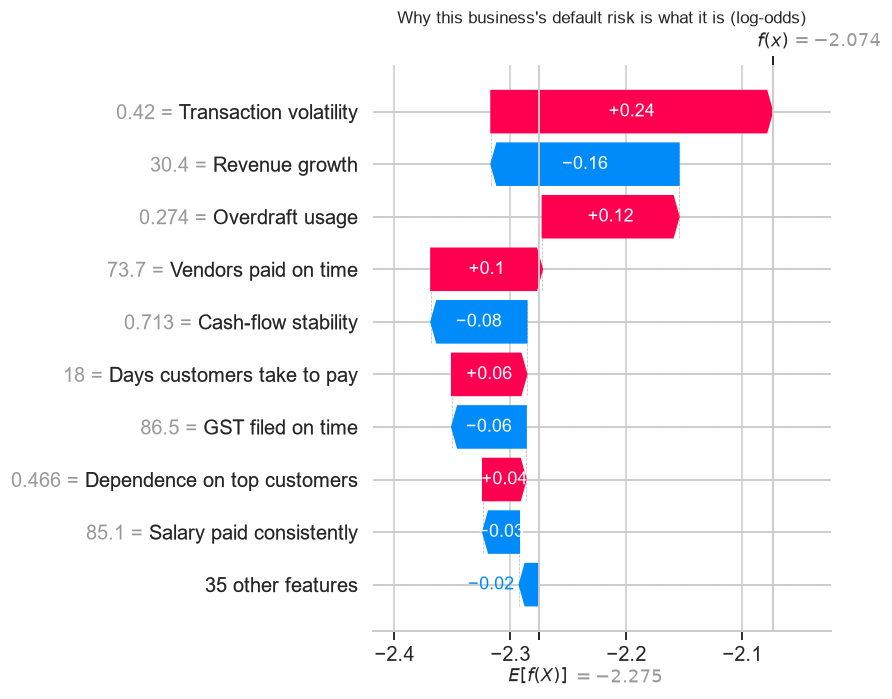

In [9]:
i = 0
shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title(f"Why this business's default risk is what it is (log-odds)")
plt.tight_layout()
plt.show()

The dashboard shows the same thing in **score points** for the health score, plus the top 4 reasons *raising* risk as **reason codes**. Lenders need these to explain a decline to the applicant.

## 7. Anomaly detection on planted fraud cases

There are no fraud labels, so we **plant** four realistic fraud patterns in clean test businesses (300 each) and measure how many we catch. The false-alarm rate is measured on the clean test set.

In [10]:
import json
from msme_health.config import ARTIFACTS
m = json.loads((ARTIFACTS / "metrics.json").read_text())["anomaly"]
det = pd.DataFrame(m["detection_rate_planted"]).T
det.loc["False alarms on clean data"] = m["false_alarm_rate_clean"]
det.style.format("{:.1%}")

,isolation_forest,rules,combined
Circular transactions,5.7%,100.0%,100.0%
Ghost payroll,12.0%,36.3%,39.7%
Hidden debt burden,12.0%,100.0%,100.0%
Inflated GST sales,14.0%,100.0%,100.0%
False alarms on clean data,2.1%,0.7%,2.5%


**Takeaway:**
- Cross-source rules catch circular transactions, inflated GST and hidden debt reliably, with under 1% false alarms.
- Ghost payroll is harder: payroll can legitimately be large.
- The Isolation Forest alone catches few planted cases. That is expected for an unsupervised detector at a 2% alert rate. It is a safety net for *unknown* patterns, not the main defence.

## 8. Credit policy: our limits vs the supplied limits

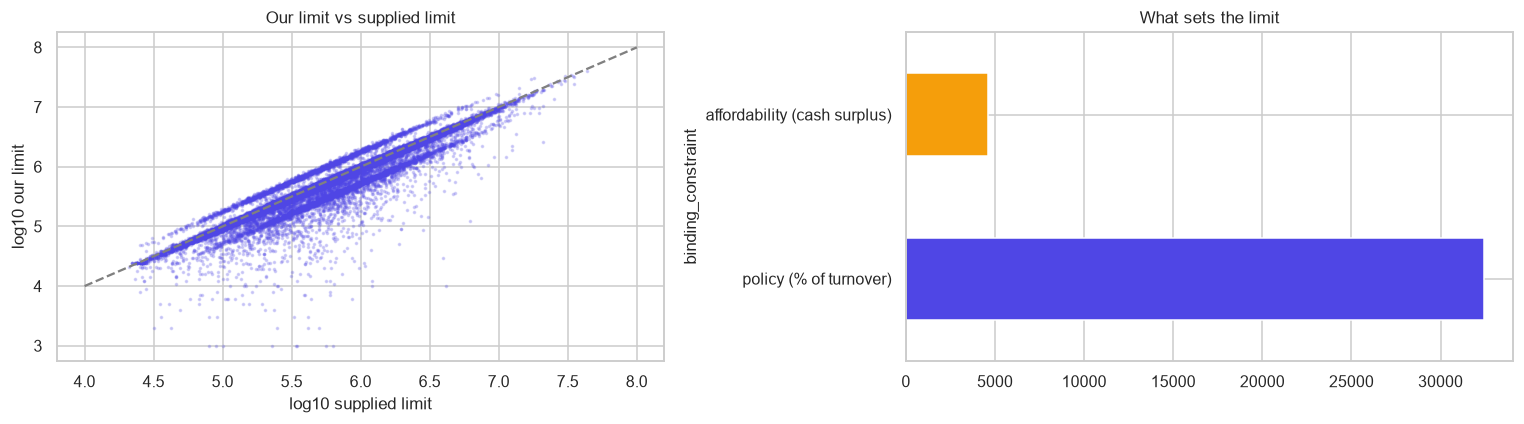

Total credit: supplied ₹3,871 Cr · ours ₹3,581 Cr


In [11]:
s = pd.read_parquet(ARTIFACTS / "scored.parquet")
both = s[(s.rec_limit > 0) & (s.Recommended_Credit_Limit_INR > 0)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(np.log10(both.Recommended_Credit_Limit_INR), np.log10(both.rec_limit), s=2, alpha=0.2, color="#4F46E5")
axes[0].plot([4, 8], [4, 8], ls="--", color="grey")
axes[0].set_xlabel("log10 supplied limit")
axes[0].set_ylabel("log10 our limit")
axes[0].set_title("Our limit vs supplied limit")
s.binding_constraint.value_counts().plot.barh(ax=axes[1], color=["#4F46E5", "#F59E0B"])
axes[1].set_title("What sets the limit")
plt.tight_layout()
plt.show()
print(f"Total credit: supplied ₹{s.Recommended_Credit_Limit_INR.sum() / 1e7:,.0f} Cr · ours ₹{s.rec_limit.sum() / 1e7:,.0f} Cr")

**Takeaway:** most limits follow the same turnover policy. The points below the diagonal are businesses where the **affordability check** lowers the limit: half their monthly surplus cannot service an EMI that large. That's the "prudent risk management" the brief asks for.

## 9. Model choice: open for discussion

| Option | Pros | Cons |
|---|---|---|
| **A. Ridge / logistic scorecard** | Equal accuracy here; fully transparent coefficients; easiest regulatory approval | Can't learn interactions if real data has them |
| **B. LightGBM + monotonic constraints** (current) | Handles missing values, interactions and real-world non-linearity; SHAP explanations; constraints keep it sensible | More complex; no accuracy gain on this data |
| **C. Champion–challenger** | Ship Ridge as champion, run LightGBM as challenger on live traffic; promote it when real defaults show lift | Two models to maintain |

**Current recommendation: C.** Start transparent; let real outcome data justify complexity. The serving code already supports swapping models.